# Task 10 — Claims process mining: where claims stall, and which will miss the settlement SLA

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Car insurance claims event log for process mining](https://www.kaggle.com/datasets/carlosalvite/car-insurance-claims-event-log-for-process-mining) (a generated log of 30,000 car-insurance claims)
**Task family:** process mining, predictive process monitoring on trace prefixes, temporal validation, drift · **Companion task:** `02_card_fraud_tabular.ipynb` (the same forward evaluation, capacity-based operating point and two-clock monitoring)

---

## The task card

> **Board question.** *About 27 car claims reach us a day, and one in ten waits more than 35 days for payment, our working settlement target. Where do claims stall, which open claims will miss the target, and can a chase list of four claims a day, updated as each claim moves, catch most of them in time to act?*

**Business context.** A motor insurer's claims operation runs on a claims-management system, a payments system and a document store; the event log is an extract from them, the raw material of *process mining*. Session 01's **streaming prediction** pattern scores a claim at each new event and feeds a **human-in-the-loop** chase list; an **offline batch** re-discovers the process weekly. The predictor reads the claims system's events and writes to the team's work queue, nothing more.

**What you will build from this notebook (see *Student tasks* at the end):**

1. a **discovery and conformance pipeline** against a reference process held in a knowledge base;
2. the given **remaining-time and SLA-breach predictor**, packaged and reproducible, on trace prefixes, evaluated forward in time, with the traps guarded by tests;
3. a **chase list sized by capacity**, and monitoring that catches a change in the process;
4. the **operational wrapper**: package, CI gate, registry, model card, process ontology with SHACL and the ablation.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Event-driven scoring in the claims flow (claims system → event stream → predictor → work queue); human-in-the-loop; AI Act and GDPR position |
| 2 · MLOps | Split by case start, prefix-level evaluation, MAE and breach F1 at capacity as the gate, conformance drift, labels that arrive up to 47 days late |
| 3 · Semantic layer | The reference process, roles and rules as an RDF ontology with SHACL; conformance features; the ablation |
| 4 · LLM/RAG | "Why is this claim late?", grounded on the trace and the reference process, and a draft customer update |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The log is **synthetic** ("artificially generated", says the publisher) and thinner than its description: every claim runs the same six steps once, each wait is an independent random draw, and there is no rework and no fraud label. The rework and the rule change the card asks about are therefore **simulated** (Sections 6 and 7) and labelled as such.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look at the process | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The reference process as a knowledge base, prefix predictors forward in time, the chase list, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | A simulated rule change after deployment, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the change your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_events` (Section 1); `case_table` and `dfg` (Section 2); `add_process`, `shacl`, `sparql`, `trace_fitness` and `prefix_conformance` (Section 3); `build_prefixes`, `kb_predict` and `scores` (Section 4); `claim_alerts` and `choose_threshold` (Section 5); `psi`, `monitor` and `why_late` (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 119,980 prefixes from 30,000 claims: train 49,065, validation 13,275 and test 19,631 (4,905 claims, breach rate 11.3 %); champion transition system on test: MAE 2.440 days against a noise floor of 2.446, AUPRC 0.440; threshold 0.43 within four chases a day, giving 3.18 chased a day at precision 0.590 and recall 0.612 (F1 0.601), a median 7.4 days before the deadline.
- **Runtime:** about 4 minutes on a laptop (233 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, json, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import lightgbm as lgb
import sklearn
import rdflib
import pyshacl
from rdflib import Graph, Literal, Namespace, RDF, RDFS, XSD
from scipy.stats import norm
from IPython.display import display
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split, GroupShuffleSplit

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 70)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                                 # one thread: faster on a shared laptop, and deterministic
KAGGLE_HANDLE = "carlosalvite/car-insurance-claims-event-log-for-process-mining"
LOG_FILE = "Insurance_claims_event_log.csv"
TRAIN_END = pd.Timestamp("2021-07-01")     # train: claims opened (FNOL) Apr 2020 – Jun 2021
VALID_END = pd.Timestamp("2021-11-01")     # validation (model choice, threshold): Jul – Oct 2021
TEST_START = pd.Timestamp("2022-01-01")    # gap Nov – Dec 2021: validation claims settle before the test starts
TEST_END = pd.Timestamp("2022-07-01")      # test, the frozen CI holdout: Jan – Jun 2022 · stream: Jul 2022 – Apr 2023
LABEL_MATURITY_DAYS = 60                   # every claim is paid within 60 days of FNOL (checked in Section 2)
SLA_DAYS = 35                              # settlement SLA, FNOL → Payment Sent (assumption ≈ P90 of training claims — task C3)
REVIEW_CAPACITY_PER_DAY = 4                # claims the team can chase per day (assumption — task C3)
SNAPSHOT = pd.Timestamp("2022-06-01 09:00")  # a morning in the test period: "which open claims will breach?"
RULE_CHANGE = pd.Timestamp("2022-10-01")   # SIMULATED rule change (the free log has none): see Section 7
HIGH_VALUE = 7_500                         # SIMULATED rule: claims of this amount or more need supporting documents
REWORK_REPEAT_P = 0.25                     # SIMULATED: share of those claims that loop twice
KB_LOOP_TARGET_H = (24.0, 96.0)            # the operations team's estimate of the new steps' waits (assumption — task E1)
PSI_ALERT = 0.25
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.9, random_state=SEED, n_jobs=N_JOBS, verbose=-1)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "claims_event_log", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
ACTS = ["FNOL", "Assign", "Decision", "Reserve", "Payment", "Close"]
NAMES = {"First Notification of Loss (FNOL)": "FNOL", "Assign Claim": "Assign", "Claim Decision": "Decision",
         "Set Reserve": "Reserve", "Payment Sent": "Payment", "Close Claim": "Close"}
SLA_H = SLA_DAYS * 24
assert (TEST_START - VALID_END).days >= LABEL_MATURITY_DAYS
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · numpy {np.__version__} · networkx {nx.__version__} · lightgbm {lgb.__version__} · "
      f"scikit-learn {sklearn.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · numpy 2.5.4 · networkx 3.7 · lightgbm 4.7.0 · scikit-learn 1.9.1 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_events`; names are dropped there.*

| Field | Value |
|---|---|
| **Source** | Kaggle `carlosalvite/car-insurance-claims-event-log-for-process-mining` ("Event logs for process mining", v1, April 2023), the free sample of a paid collection; only this file is used |
| **Licence** | ODbL for the database, DbCL for its contents (as listed on Kaggle) |
| **Provenance** | Generated; the publisher states that the personal names are fake |
| **Size** | 180,000 events, 30,000 claims, 6 activities; FNOL 6 Apr 2020 – 15 Apr 2023, last event 26 May 2023 |
| **Files** | `Insurance_claims_event_log.csv` (32.5 MB) |
| **Schema** | `case_id` (UUID), `activity_name`, `timestamp`; per claim: `claim_amount` (1,000–10,000, currency not stated), `claimant_age`, `type_of_policy`, `car_make`, `car_model` (one per make), `car_year`, `type_of_accident`, `user_type` (Human / RPA), three name columns |
| **Label** | None supplied. We derive the **remaining time** to *Payment Sent*, and **SLA breach**: payment more than 35 days after FNOL (10.7 % of claims) |
| **Window used here** | All of it (19 MB in memory). By FNOL date: train Apr 2020 – Jun 2021, validate Jul – Oct 2021, gap Nov – Dec 2021 (validation claims settle), test Jan – Jun 2022 (frozen CI holdout), stream Jul 2022 – Apr 2023 |
| **PII** | Names are fake but dropped on load; `claimant_age` is a protected characteristic and never a feature; `case_id` is a random UUID |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **Time order and file order disagree for 735 claims (2.45 %).** The file lists every claim as FNOL → Assign → Decision → Reserve → Payment → Close; sorted by timestamp, 735 are decided before they are assigned, or closed before they are paid (Trap 3).
2. ⚠ **One path, no rework.** Every claim has each of the six activities exactly once. The description promises "reworks and potential fraudulent cases"; the free log has neither.
3. ⚠ **Clockwork waits.** Assignment takes a median 15 days and every later step 5, all with the same 2-day spread, independent of each other and of every claim attribute; events arrive around the clock (Trap 3).
4. **No claim is open at extraction.** A real extract cuts claims in flight; training on finished claims only would favour the fast ones.
5. **No workforce.** 25,862 agent and 25,797 adjuster names for 30,000 claims: names are drawn per claim, so resource mining is impossible.
6. **Description and file disagree.** It lists an accident date (absent) and says claims belong to 2020–2022 (FNOLs run to mid-April 2023).

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

PERSONAL = ["claimant_name", "agent_name", "adjuster_name"]

def load_events() -> pd.DataFrame:
    cache = PROCESSED / "10_claims_events.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    raw = pd.read_csv(get_raw(LOG_FILE))
    # ---- governance on load: the names are fake (publisher's disclaimer), but we treat them as personal ----
    distinct = {c: raw[c].nunique() for c in PERSONAL}
    ev = raw.drop(columns=PERSONAL)
    ev["timestamp"] = pd.to_datetime(ev.timestamp)
    ev["activity"] = ev.pop("activity_name").map(NAMES)
    ev["file_seq"] = ev.groupby("case_id", sort=False).cumcount()   # position in the file, kept only to study the generator
    for c in ["type_of_policy", "car_make", "car_model", "type_of_accident", "user_type"]:
        ev[c] = ev[c].astype("category")
    pd.Series(distinct).to_json(PROCESSED / "10_distinct_names.json")
    ev.to_parquet(cache)
    return ev

ev = load_events()
distinct_names = pd.read_json(PROCESSED / "10_distinct_names.json", typ="series")
ev = ev.sort_values(["case_id", "timestamp"], kind="stable").reset_index(drop=True)   # process mining orders by time
print(f"{len(ev):,} events · {ev.case_id.nunique():,} claims · {ev.activity.nunique()} activities · "
      f"{ev.timestamp.min():%d %b %Y} – {ev.timestamp.max():%d %b %Y} · {ev.memory_usage(deep=True).sum() / 1e6:.0f} MB · "
      f"names dropped on load (distinct: " + ", ".join(f"{k} {v:,}" for k, v in distinct_names.items()) + ")")
display(ev.head(6).drop(columns=["file_seq"]))

180,000 events · 30,000 claims · 6 activities · 06 Apr 2020 – 26 May 2023 · 19 MB · names dropped on load (distinct: claimant_name 25,778, agent_name 25,862, adjuster_name 25,797)


,case_id,timestamp,claim_amount,claimant_age,type_of_policy,car_make,car_model,car_year,type_of_accident,user_type,activity
0,000112d5-9d04-450f-820f-3edfc0626cf9,2022-04-19 01:47:54.857481,9266.19,60,Comprehensive,Hyundai,Elantra,2021,Head-on,Human,FNOL
1,000112d5-9d04-450f-820f-3edfc0626cf9,2022-05-01 18:11:26.417687,9266.19,60,Comprehensive,Hyundai,Elantra,2021,Head-on,Human,Assign
2,000112d5-9d04-450f-820f-3edfc0626cf9,2022-05-03 07:01:46.479057,9266.19,60,Comprehensive,Hyundai,Elantra,2021,Head-on,Human,Decision
3,000112d5-9d04-450f-820f-3edfc0626cf9,2022-05-08 09:26:47.468433,9266.19,60,Comprehensive,Hyundai,Elantra,2021,Head-on,Human,Reserve
4,000112d5-9d04-450f-820f-3edfc0626cf9,2022-05-15 16:12:46.119925,9266.19,60,Comprehensive,Hyundai,Elantra,2021,Head-on,Human,Payment
5,000112d5-9d04-450f-820f-3edfc0626cf9,2022-05-20 15:04:57.957352,9266.19,60,Comprehensive,Hyundai,Elantra,2021,Head-on,Human,Close


## 2 · First look: the process the log records

*Part A · Explore · read; package `case_table` and `dfg`; the assignment wait is the board's first answer.*

Process mining needs three columns: a **case** (`case_id`), an **activity** and a **timestamp**. A case's events in time order form its *trace*; identical traces form a *variant*. Counting which activity directly follows which, and how long the wait was, gives the **directly-follows graph** (DFG), the process map a claims-operations head sees first. Pandas and networkx are enough.

In [3]:
CASE_COLS = ["claim_amount", "claimant_age", "type_of_policy", "car_make", "car_year", "type_of_accident", "user_type"]

def case_table(ev: pd.DataFrame) -> pd.DataFrame:
    g = ev.groupby("case_id", sort=False)
    c = g[CASE_COLS].first()
    c["start"], c["end"] = g.timestamp.min(), g.timestamp.max()
    c["paid"] = ev[ev.activity == "Payment"].groupby("case_id").timestamp.max()
    c["variant"] = g.activity.agg(">".join)
    c["n_events"] = g.size()
    c["to_pay_h"] = (c.paid - c.start).dt.total_seconds() / 3600
    c["breach"] = (c.to_pay_h > SLA_H).astype(int)
    c["period"] = np.select([c.start < TRAIN_END, c.start < VALID_END, c.start < TEST_START, c.start < TEST_END],
                            ["train", "valid", "gap", "test"], "stream")
    c["month"] = c.start.dt.to_period("M")
    return c

cases = case_table(ev)
REF_VARIANT = cases[cases.period == "train"].variant.value_counts().index[0]
variants = cases.variant.value_counts().rename("claims").to_frame()
variants["share"] = variants.claims / len(cases)
print(f"{len(variants)} variants (time-ordered) · every claim has {cases.n_events.min()}–{cases.n_events.max()} events · "
      f"repeated activities: {int((ev.groupby(['case_id', 'activity']).size() > 1).sum())}")
display(variants.head(6).style.format({"claims": "{:,}", "share": "{:.2%}"}))

# directly-follows graph: consecutive events within a claim, with frequency and median waiting time
def dfg(ev: pd.DataFrame) -> pd.DataFrame:
    e = ev[["case_id", "activity", "timestamp"]].copy()
    e["prev"] = e.groupby("case_id").activity.shift()
    e["wait_h"] = e.groupby("case_id").timestamp.diff().dt.total_seconds() / 3600
    return (e.dropna(subset=["prev"]).groupby(["prev", "activity"], observed=True)
             .agg(n=("wait_h", "size"), median_wait_h=("wait_h", "median"), p90_wait_h=("wait_h", lambda s: s.quantile(0.9)))
             .reset_index().sort_values("n", ascending=False))

D = dfg(ev)
G = nx.DiGraph()
for r in D.itertuples(index=False):
    G.add_edge(r.prev, r.activity, n=r.n, wait=r.median_wait_h)
main = [(a, b) for a, b in zip(ACTS[:-1], ACTS[1:])]
print(f"DFG: {G.number_of_nodes()} activities, {G.number_of_edges()} directly-follows edges; "
      f"{sum(G.edges[e]['n'] for e in main) / D.n.sum():.1%} of transitions follow the main path")
display(D.head(8).style.format({"n": "{:,}", "median_wait_h": "{:.0f}", "p90_wait_h": "{:.0f}"}).hide(axis="index"))

15 variants (time-ordered) · every claim has 6–6 events · repeated activities: 0


,claims,share
variant,,
FNOL>Assign>Decision>Reserve>Payment>Close,"29,265",97.55%
FNOL>Decision>Assign>Reserve>Payment>Close,188,0.63%
FNOL>Assign>Decision>Payment>Reserve>Close,180,0.60%
FNOL>Assign>Reserve>Decision>Payment>Close,175,0.58%
FNOL>Assign>Decision>Reserve>Close>Payment,173,0.58%
FNOL>Assign>Payment>Decision>Reserve>Close,4,0.01%


DFG: 6 activities, 20 directly-follows edges; 98.6% of transitions follow the main path


prev,activity,n,median_wait_h,p90_wait_h
FNOL,Assign,"29,807",360,422
Payment,Close,"29,633",120,181
Assign,Decision,"29,621",121,182
Reserve,Payment,"29,456",120,182
Decision,Reserve,"29,444",121,182
Assign,Reserve,371,107,168
Reserve,Close,359,104,176
Decision,Payment,358,107,169


FNOL 06 Apr 2020 – 15 Apr 2023 · 27.1 new claims a day · days to payment: median 30.1, P90 35.1 (training claims 35.1), max 47.0 · SLA 35 d breached by 10.7%


,median_h,sd_h,p90_h,min_h,share_of_settlement
Assign,360,48,422,189,50%
Decision,121,48,181,-64,17%
Reserve,121,48,182,-51,17%
Payment,120,48,182,-43,17%
Close,119,48,180,-66,—


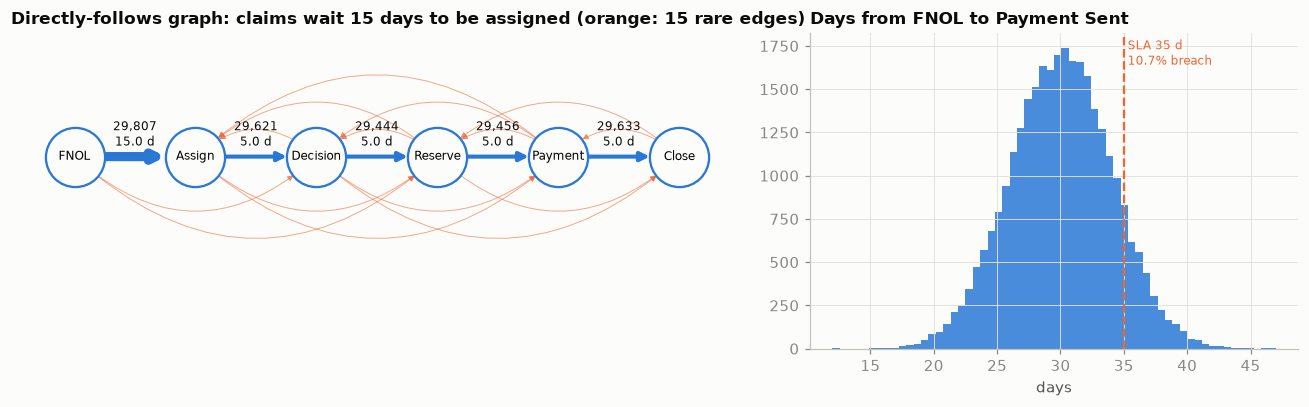

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
pos = {a: (i, 0) for i, a in enumerate(ACTS)}
other = [e for e in G.edges if e not in main]
nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#fcfcfb", edgecolors=SERIES[0], node_size=1500, linewidths=1.5)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
nx.draw_networkx_edges(G, pos, edgelist=main, ax=ax, width=[1 + 5 * G.edges[e]["wait"] / 360 for e in main],
                       edge_color=SERIES[0], node_size=1500, arrowsize=12)
nx.draw_networkx_edges(G, pos, edgelist=other, ax=ax, width=0.6, edge_color=SERIES[1], alpha=0.6, node_size=1500,
                       connectionstyle="arc3,rad=0.45", arrowsize=8)
for a, b in main:
    ax.text((pos[a][0] + pos[b][0]) / 2, 0.05, f"{G.edges[a, b]['n']:,}\n{G.edges[a, b]['wait'] / 24:.1f} d",
            ha="center", va="bottom", fontsize=8, color=INK)
ax.set_ylim(-1.4, 0.9); ax.axis("off")
ax.set_title(f"Directly-follows graph: claims wait {G.edges['FNOL', 'Assign']['wait'] / 24:.0f} days to be assigned "
             f"(orange: {len(other)} rare edges)")
ax = axes[1]
ax.hist(cases.to_pay_h / 24, bins=60, color=SERIES[0], alpha=0.85)
ax.axvline(SLA_DAYS, color=SERIES[1], lw=1.5, ls="--")
ax.text(SLA_DAYS + 0.3, ax.get_ylim()[1] * 0.9, f"SLA {SLA_DAYS} d\n{cases.breach.mean():.1%} breach", color=SERIES[1], fontsize=8)
ax.set_title("Days from FNOL to Payment Sent"); ax.set_xlabel("days")
plt.tight_layout()

# step waits along the reference path (one row per claim: safe only because no activity repeats; see Trap 4)
wide = ev.pivot(index="case_id", columns="activity", values="timestamp")[ACTS]
waits = pd.DataFrame({b: (wide[b] - wide[a]).dt.total_seconds() / 3600 for a, b in zip(ACTS[:-1], ACTS[1:])})
tr_c = cases.period == "train"
step_stats = waits.loc[cases.index[tr_c]].agg(["median", "std", lambda s: s.quantile(0.9), "min"]).T
step_stats.columns = ["median_h", "sd_h", "p90_h", "min_h"]
step_stats["share_of_settlement"] = step_stats.median_h / cases.loc[tr_c, "to_pay_h"].median()
step_stats.loc[["Close"], "share_of_settlement"] = np.nan
print(f"FNOL {cases.start.min():%d %b %Y} – {cases.start.max():%d %b %Y} · {len(cases) / ((cases.start.max() - cases.start.min()).days + 1):.1f} new claims a day · "
      f"days to payment: median {cases.to_pay_h.median() / 24:.1f}, P90 {cases.to_pay_h.quantile(0.9) / 24:.1f} "
      f"(training claims {cases.loc[tr_c, 'to_pay_h'].quantile(0.9) / 24:.1f}), max {cases.to_pay_h.max() / 24:.1f} · "
      f"SLA {SLA_DAYS} d breached by {cases.breach.mean():.1%}")
display(step_stats.style.format({"median_h": "{:.0f}", "sd_h": "{:.0f}", "p90_h": "{:.0f}", "min_h": "{:.0f}",
                                 "share_of_settlement": "{:.0%}"}, na_rep="—"))

The board's first question has a one-line answer: **claims stall before anyone picks them up.** The FNOL → Assign wait has a median of 15.0 days, half the 30.1-day median time to payment; every later step takes 5.0. The 15 other DFG edges carry 1.4 % of transitions, each a pair of steps in the wrong order. Time to payment is a near-perfect bell (P90 35.1 days), so we set the SLA at 35 days, an assumption missed by 10.7 % of claims (task C3). Note the negative minimum waits (Trap 3).

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The reference process as a knowledge base, and conformance

*Part B · Given model · package the KB (`add_process`, `shacl`, `sparql`) and `trace_fitness`, `prefix_conformance`; E1 extends the KB.*

Conformance needs a reference process, stated before the data is judged. Ours is the most frequent variant (97.55 % of claims), also the publisher's "standard process flow". It lives in a small RDF graph (Sessions 07–09) with what the log does not say: the **role** behind each activity (our reading), each **step's** median, spread and P90 wait, and the **rules**: the SLA, a stall rule, and *a fraud flag needs a human's approval*, a SHACL shape an unapproved flag fails. Competency questions: *What must precede a payment? Where do claims wait longest, and who owns that step? Which process applies to this claim?*

In [5]:
CP = Namespace("https://ari3217.example/claims#")
SH = Namespace("http://www.w3.org/ns/shacl#")
ROLE_OF = {"FNOL": "ClaimsAgent", "Assign": "ClaimsAgent", "Decision": "Adjuster", "Reserve": "Adjuster",
           "Payment": "PaymentsTeam", "Close": "ClaimsAgent"}            # our reading: the log does not say who does what
FULL = {v: k for k, v in NAMES.items()}

def add_process(kb, name, steps, applies_from, min_amount, comment):
    p = CP[name]
    kb.add((p, RDF.type, CP.Process)); kb.add((p, RDFS.comment, Literal(comment)))
    kb.add((p, CP.appliesFrom, Literal(applies_from.date(), datatype=XSD.date)))
    kb.add((p, CP.minAmount, Literal(float(min_amount))))
    for i, (act, target, sd, p90) in enumerate(steps, start=1):
        s = CP[f"{name}_step{i}"]
        kb.add((p, CP.hasStep, s)); kb.add((s, RDF.type, CP.Step)); kb.add((s, CP.position, Literal(i)))
        kb.add((s, CP.activity, CP[act])); kb.add((s, CP.targetWaitHours, Literal(round(float(target), 1))))
        kb.add((s, CP.waitSdHours, Literal(round(float(sd), 1)))); kb.add((s, CP.p90WaitHours, Literal(round(float(p90), 1))))
    for (a, *_), (b, *_) in zip(steps[:-1], steps[1:]):
        if a != b:
            kb.add((CP[a], CP.precedes, CP[b]))

kb = Graph(); kb.bind("cp", CP)
for role, human in [("ClaimsAgent", True), ("Adjuster", True), ("PaymentsTeam", True), ("RPABot", False)]:
    kb.add((CP[role], RDF.type, CP.Role)); kb.add((CP[role], CP.isHuman, Literal(human)))
for a in ACTS:
    kb.add((CP[a], RDF.type, CP.Activity)); kb.add((CP[a], RDFS.label, Literal(FULL[a])))
    kb.add((CP[a], CP.performedBy, CP[ROLE_OF[a]]))
std_steps = [("FNOL", 0.0, 0.0, 0.0)] + [(a, *step_stats.loc[a, ["median_h", "sd_h", "p90_h"]]) for a in ACTS[1:]]
add_process(kb, "StandardProcess", std_steps, pd.Timestamp("2020-01-01"), 0,
            f"Derived from the most frequent variant of training claims; equals the publisher's stated flow")
for rule, text in [("SettlementSLA", f"Payment Sent within {SLA_DAYS} days of FNOL (assumption)"),
                   ("StallRule", "A claim is stalled when its current wait exceeds the next step's P90"),
                   ("FraudFlagRule", "A fraud flag needs approval by a human role before any action on the claim")]:
    kb.add((CP[rule], RDF.type, CP.Rule)); kb.add((CP[rule], RDFS.comment, Literal(text)))
kb.add((CP.SettlementSLA, CP.days, Literal(SLA_DAYS)))

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix cp: <https://ari3217.example/claims#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
cp:ActivityShape a sh:NodeShape ; sh:targetClass cp:Activity ;
  sh:property [ sh:path cp:performedBy ; sh:class cp:Role ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "activity without exactly one role" ] .
cp:StepShape a sh:NodeShape ; sh:targetClass cp:Step ;
  sh:property [ sh:path cp:activity ; sh:class cp:Activity ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path cp:position ; sh:datatype xsd:integer ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path cp:targetWaitHours ; sh:minInclusive 0 ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "step target missing or negative" ] .
cp:ProcessShape a sh:NodeShape ; sh:targetClass cp:Process ;
  sh:property [ sh:path cp:hasStep ; sh:minCount 2 ] ;
  sh:property [ sh:path cp:appliesFrom ; sh:datatype xsd:date ; sh:minCount 1 ; sh:maxCount 1 ] .
cp:FraudFlagShape a sh:NodeShape ; sh:targetClass cp:FraudFlag ;
  sh:property [ sh:path cp:approvedBy ; sh:minCount 1 ; sh:message "fraud flag without an approval" ] ;
  sh:sparql [ sh:message "fraud flag approved by a non-human role" ; sh:select \"\"\"
     PREFIX cp: <https://ari3217.example/claims#>
     SELECT $this WHERE { $this cp:approvedBy ?r . ?r cp:isHuman false . }\"\"\" ] .
"""
shapes = Graph().parse(data=SHAPES, format="turtle")

def shacl(g):
    ok, rep, _ = pyshacl.validate(g, shacl_graph=shapes)
    return ok, sorted({str(rep.value(r, SH.resultMessage)) for r in rep.subjects(RDF.type, SH.ValidationResult)})

ok, msgs = shacl(kb)
print(f"KB: {len(kb)} triples · conforms: {ok}")
# governance as a shape: a fraud flag the model raises must be approved by a person
for label, approver in [("no approval", None), ("approved by the RPA bot", "RPABot"), ("approved by an adjuster", "Adjuster")]:
    g = Graph() + kb
    g.add((CP.flag1, RDF.type, CP.FraudFlag))
    if approver:
        g.add((CP.flag1, CP.approvedBy, CP[approver]))
    print(f"  fraud flag, {label:24s} → conforms: {shacl(g)[0]} {shacl(g)[1]}")

def sparql(q):
    return pd.DataFrame([[v.toPython() if v is not None else None for v in row] for row in kb.query(q, initNs={"cp": CP, "rdfs": RDFS})])

CQ1 = "SELECT ?label WHERE { ?a cp:precedes+ cp:Payment ; rdfs:label ?label . }"
CQ2 = """SELECT ?label ?role ?target ?p90 WHERE { cp:StandardProcess cp:hasStep ?s . ?s cp:activity ?a ; cp:targetWaitHours ?target ;
         cp:p90WaitHours ?p90 . ?a rdfs:label ?label ; cp:performedBy ?r . BIND(STRAFTER(STR(?r), "#") AS ?role) } ORDER BY DESC(?target)"""
print("CQ1 · must precede Payment Sent:", ", ".join(sorted(sparql(CQ1)[0])))
print("CQ2 · where claims wait longest, and who owns the step:")
display(sparql(CQ2).head(3).rename(columns={0: "step", 1: "role (our reading)", 2: "target wait (h)", 3: "P90 (h)"}))

KB: 84 triples · conforms: True


  fraud flag, no approval              → conforms: False ['fraud flag without an approval']
  fraud flag, approved by the RPA bot  → conforms: False ['fraud flag approved by a non-human role']
  fraud flag, approved by an adjuster  → conforms: True []
CQ1 · must precede Payment Sent: Assign Claim, Claim Decision, First Notification of Loss (FNOL), Set Reserve
CQ2 · where claims wait longest, and who owns the step:


,step,role (our reading),target wait (h),P90 (h)
0,Assign Claim,ClaimsAgent,359.9,421.8
1,Claim Decision,Adjuster,120.8,181.1
2,Set Reserve,Adjuster,120.6,181.9


Conformance is **alignment fitness**, which for a single-path reference has a closed form: 2·LCS / (|trace| + |reference|), with LCS the longest common subsequence (1 for a perfect trace, 0.83 for one swapped pair). Applied to a *prefix*, it gives Section 4's conformance features. The code reads the reference from the KB, so a new rule needs no code change.

In [6]:
def reference_processes(kb) -> dict:
    """Every process in the KB with its applicability and ordered steps: code reads the rules, it does not hold them."""
    q = """SELECT ?p ?from ?min ?pos ?act ?t ?sd ?p90 WHERE { ?p a cp:Process ; cp:appliesFrom ?from ; cp:minAmount ?min ; cp:hasStep ?s .
           ?s cp:position ?pos ; cp:activity ?a ; cp:targetWaitHours ?t ; cp:waitSdHours ?sd ; cp:p90WaitHours ?p90 .
           BIND(STRAFTER(STR(?a), "#") AS ?act) } ORDER BY ?p ?pos"""
    rows = pd.DataFrame([[v.toPython() for v in r] for r in kb.query(q, initNs={"cp": CP})],
                        columns=["process", "from", "min", "pos", "act", "target", "sd", "p90"])
    rows["process"] = rows.process.astype(str).str.split("#").str[1]
    return {p: {"from": pd.Timestamp(d["from"].iat[0]), "min": d["min"].iat[0],
                "steps": list(zip(d.act, d.target, d.sd, d.p90))} for p, d in rows.groupby("process")}

def process_of(cases: pd.DataFrame, procs: dict) -> pd.Series:
    """The most specific process that applies to each claim (highest amount threshold in force at FNOL)."""
    out = pd.Series("StandardProcess", index=cases.index)
    for name, p in sorted(procs.items(), key=lambda kv: kv[1]["min"]):
        out[(cases.start >= p["from"]) & (cases.claim_amount >= p["min"])] = name
    return out

def lcs_table(a, b):
    L = np.zeros((len(a) + 1, len(b) + 1), dtype=int)
    for i, x in enumerate(a):
        for j, y in enumerate(b):
            L[i + 1, j + 1] = L[i, j] + 1 if x == y else max(L[i, j + 1], L[i + 1, j])
    return L

def trace_fitness(trace, ref):
    """Alignment fitness against a sequential model: 1 − cost / worst cost = 2·LCS / (|trace| + |ref|)."""
    return 2 * lcs_table(trace, ref)[-1, -1] / (len(trace) + len(ref))

def prefix_conformance(prefix, steps):
    """Fitness and deviations of a prefix against the best-matching reference prefix, and what the reference still owes."""
    ref = [s[0] for s in steps]
    L, k = lcs_table(prefix, ref), len(prefix)
    j = max(range(1, len(ref) + 1), key=lambda j: 2 * L[k, j] / (k + j))
    counts, seen, left, mu, var = {}, {}, 0, 0.0, 0.0
    for a in prefix:
        counts[a] = counts.get(a, 0) + 1
    for act, target, sd, _ in steps[1:ref.index("Payment") + 1]:         # outstanding steps up to the payment
        seen[act] = seen.get(act, 0) + 1
        if counts.get(act, 0) < seen[act]:
            left, mu, var = left + 1, mu + target, var + sd ** 2
    return 2 * L[k, j] / (k + j), k - L[k, j], left, mu, var

PROCS = reference_processes(kb)
REF = [s[0] for s in PROCS["StandardProcess"]["steps"]]
cases["fitness"] = [trace_fitness(v.split(">"), REF) for v in cases.variant]
conf = cases.fitness == 1
# which precedence of the reference does each deviating claim break?
viol = {f"{b} before {a}": int((wide[b] < wide[a]).sum()) for a, b in zip(ACTS[:-1], ACTS[1:])}
print(f"reference (from the KB): {' → '.join(REF)} · conforming claims {conf.mean():.2%} · "
      f"mean fitness {cases.fitness.mean():.4f} · deviating claims {int((~conf).sum())}")
print("broken precedences:", viol)

reference (from the KB): FNOL → Assign → Decision → Reserve → Payment → Close · conforming claims 97.55% · mean fitness 0.9959 · deviating claims 735
broken precedences: {'Assign before FNOL': 0, 'Decision before Assign': 193, 'Reserve before Decision': 183, 'Payment before Reserve': 189, 'Close before Payment': 178}


97.55 % of claims fit perfectly (mean fitness 0.996). The other 735 break one or two precedences: 193 were decided before assignment, 178 closed before payment. A compliance officer would want to hear about the 178; Trap 3 explains why not yet.

## 4 · Predicting from prefixes, forward in time

*Part B · Given model · package `build_prefixes`, `kb_predict` and `scores` unchanged and reproduce the numbers (C2).*

An open claim is a **prefix**, its trace so far. After every event before *Payment Sent* we predict the **remaining time** to payment and whether the claim will **breach** the SLA. Features use only the prefix, and the split is by **FNOL date**, so a claim's prefixes stay together (Trap 1). Four predictors:

- **Transition system** (van der Aalst et al., 2011): the state is the set of activities done; it predicts the median remaining time of training prefixes in that state, and the share that would have overrun this claim's time left.
- **KB reference process, no training**: the KB's targets for the steps still owed, and a normal approximation.
- **LightGBM, sequence only**: prefix length, last activity, activity counts, elapsed time, last wait.
- **LightGBM, sequence + KB conformance**: adds prefix fitness, deviations, steps owed, their expected duration and the *slack* (SLA − elapsed − expected); the regressor learns a correction to the KB's expectation.

As the waits are independent normal draws, we can also compute the **noise floor**, the error of a predictor that knows the generator.

In [7]:
SEQ = ["k", "last_act", "elapsed_h", "since_prev_h"] + [f"n_{a}" for a in ACTS]
CASE = ["claim_amount", "type_of_policy", "type_of_accident", "user_type", "car_make", "car_year"]   # never claimant_age
CONF = ["kb_fitness", "kb_deviations", "kb_steps_left", "kb_expected_left_h", "kb_slack_h"]

def build_prefixes(ev: pd.DataFrame, cases: pd.DataFrame, procs: dict) -> pd.DataFrame:
    """One row per prefix: the claim as it stands just after each event before Payment Sent. As-of features only."""
    e = ev.join(cases[["start", "paid", "breach", "period", "month"]], on="case_id")
    e = e[e.timestamp < e.paid].copy()
    g = e.groupby("case_id", sort=False)
    e["k"] = g.cumcount() + 1
    e["elapsed_h"] = (e.timestamp - e.start).dt.total_seconds() / 3600
    e["since_prev_h"] = g.timestamp.diff().dt.total_seconds().fillna(0) / 3600
    e["remaining_h"] = (e.paid - e.timestamp).dt.total_seconds() / 3600
    for a in ACTS:
        e[f"n_{a}"] = (e.activity == a).astype(int).groupby(e.case_id).cumsum()
    e["last_act"] = pd.Categorical(e.activity.where(e.activity.isin(ACTS)), categories=ACTS)   # unknown at training time → missing
    proc = e.case_id.map(process_of(cases, procs)).to_numpy()
    cache, out, prev, seq = {}, np.empty((len(e), 5)), None, []
    for i, (c, a) in enumerate(zip(e.case_id.to_numpy(), e.activity.to_numpy())):
        seq = [a] if c != prev else seq + [a]
        prev = c
        key = (proc[i], tuple(seq))
        if key not in cache:
            cache[key] = prefix_conformance(seq, procs[proc[i]]["steps"])
        out[i] = cache[key]
    e[["kb_fitness", "kb_deviations", "kb_steps_left", "kb_expected_left_h", "kb_var_left"]] = out
    e["kb_slack_h"] = SLA_H - e.elapsed_h - e.kb_expected_left_h
    e["state"] = [">".join(a for a, n in zip(ACTS, row) if n) for row in e[[f"n_{a}" for a in ACTS]].to_numpy()]
    return e.reset_index(drop=True)

t0 = time.time()
pre = build_prefixes(ev, cases, PROCS)
P = {p: (pre.period == p).to_numpy() for p in ["train", "valid", "gap", "test", "stream"]}
print(f"{len(pre):,} prefixes from {pre.case_id.nunique():,} claims in {time.time() - t0:.1f}s · "
      + " · ".join(f"{p} {P[p].sum():,}" for p in P) + f" · already past the SLA at the prefix: {int((pre.elapsed_h > SLA_H).sum())}")

119,980 prefixes from 30,000 claims in 2.1s · train 49,065 · valid 13,275 · gap 6,869 · test 19,631 · stream 31,140 · already past the SLA at the prefix: 60


In [8]:
class TransitionSystem:
    """Process-mining baseline: the state is the set of activities done; remaining time is read off training prefixes."""
    def fit(self, d):
        self.R = {s: np.sort(v.to_numpy()) for s, v in d.groupby("state").remaining_h}
        self.all = np.sort(d.remaining_h.to_numpy())
        return self
    def predict(self, d):
        rem, p = np.empty(len(d)), np.empty(len(d))
        for s, idx in d.groupby("state").indices.items():
            R = self.R.get(s, self.all)
            rem[idx] = np.median(R)
            p[idx] = 1 - np.searchsorted(R, SLA_H - d.elapsed_h.to_numpy()[idx], side="right") / len(R)
        return rem, p

def kb_predict(d):
    """The reference process alone: outstanding step targets, and a normal approximation for the breach."""
    sd = np.sqrt(d.kb_var_left.to_numpy()).clip(1)
    return d.kb_expected_left_h.to_numpy(), 1 - norm.cdf(d.kb_slack_h.to_numpy() / sd)

class LGBPrefix:
    """LightGBM on prefix features; with the KB, the regressor learns a correction to the reference's expectation."""
    def __init__(self, cols, prior=False):
        self.cols, self.prior = cols, prior
    def fit(self, d):
        base = d.kb_expected_left_h if self.prior else 0
        self.reg = lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(d[self.cols], d.remaining_h - base)
        self.clf = lgb.LGBMClassifier(**LGB_PARAMS).fit(d[self.cols], d.breach)
        return self
    def predict(self, d):
        base = d.kb_expected_left_h.to_numpy() if self.prior else 0
        return self.reg.predict(d[self.cols]) + base, self.clf.predict_proba(d[self.cols])[:, 1]

def scores(d, rem, p, name):
    err = np.abs(rem - d.remaining_h.to_numpy()) / 24
    kb_ = d.k.clip(upper=4).to_numpy()
    r = {"model": name, "MAE (days)": err.mean(), "AUPRC": average_precision_score(d.breach, p)}
    for k in [1, 2, 3, 4]:
        r[f"MAE k={k}{'+' if k == 4 else ''}"] = err[kb_ == k].mean()
    for k in [2, 3, 4]:
        r[f"AUPRC k={k}{'+' if k == 4 else ''}"] = average_precision_score(d.breach[kb_ == k], p[kb_ == k])
    return r

tr, va, te = pre[P["train"]], pre[P["valid"]], pre[P["test"]]
models = {"transition system (process-mining baseline)": TransitionSystem().fit(tr),
          "LightGBM · sequence only": LGBPrefix(SEQ).fit(tr),
          "LightGBM · sequence + KB conformance": LGBPrefix(SEQ + CONF, prior=True).fit(tr)}
pred = {(n, s): m.predict(d) for n, m in models.items() for s, d in [("valid", va), ("test", te)]}
pred.update({("KB reference process, no training", s): kb_predict(d) for s, d in [("valid", va), ("test", te)]})
res = pd.DataFrame([scores(te, *pred[(n, "test")], n) for n in dict.fromkeys(n for n, _ in pred)]).set_index("model")
floor = np.sqrt(te.kb_var_left) * np.sqrt(2 / np.pi) / 24       # E|X − median| of a normal: the generator's noise floor
res.loc["noise floor (independent normal waits)", ["MAE (days)"] + [f"MAE k={k}{'+' if k == 4 else ''}" for k in [1, 2, 3, 4]]] = \
    [floor.mean()] + [floor[te.k.clip(upper=4) == k].mean() for k in [1, 2, 3, 4]]
print(f"test: {len(te):,} prefixes of {te.case_id.nunique():,} claims · breach rate {cases.loc[cases.period == 'test', 'breach'].mean():.1%} "
      f"· AUPRC at k=1 (FNOL only) is the base rate for every model: {average_precision_score(te.breach[te.k == 1], pred[('LightGBM · sequence only', 'test')][1][te.k.to_numpy() == 1]):.3f}")
display(res.style.format("{:.3f}", na_rep="—"))

test: 19,631 prefixes of 4,905 claims · breach rate 11.3% · AUPRC at k=1 (FNOL only) is the base rate for every model: 0.113


,MAE (days),AUPRC,MAE k=1,MAE k=2,MAE k=3,MAE k=4+,AUPRC k=2,AUPRC k=3,AUPRC k=4+
model,,,,,,,,,
transition system (process-mining baseline),2.440,0.440,3.217,2.752,2.233,1.559,0.327,0.483,0.707
LightGBM · sequence only,2.454,0.417,3.217,2.772,2.256,1.575,0.303,0.442,0.679
LightGBM · sequence + KB conformance,2.454,0.417,3.217,2.775,2.250,1.576,0.300,0.449,0.680
"KB reference process, no training",2.481,0.410,3.218,2.877,2.243,1.586,0.273,0.482,0.688
noise floor (independent normal waits),2.446,—,3.188,2.756,2.257,1.586,—,—,—


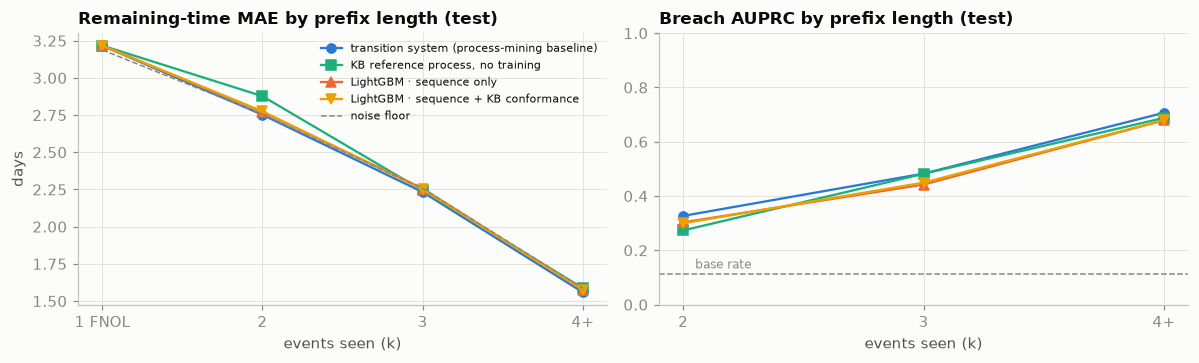

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ks = [1, 2, 3, 4]
for (name, color, mk) in [("transition system (process-mining baseline)", SERIES[0], "o"), ("KB reference process, no training", SERIES[2], "s"),
                          ("LightGBM · sequence only", SERIES[1], "^"), ("LightGBM · sequence + KB conformance", SERIES[3], "v")]:
    axes[0].plot(ks, [res.loc[name, f"MAE k={k}{'+' if k == 4 else ''}"] for k in ks], marker=mk, color=color, lw=1.5, label=name)
    axes[1].plot(ks[1:], [res.loc[name, f"AUPRC k={k}{'+' if k == 4 else ''}"] for k in ks[1:]], marker=mk, color=color, lw=1.5, label=name)
axes[0].plot(ks, [res.loc["noise floor (independent normal waits)", f"MAE k={k}{'+' if k == 4 else ''}"] for k in ks], color=MUTED, ls="--", lw=1, label="noise floor")
axes[0].set_title("Remaining-time MAE by prefix length (test)"); axes[0].set_xlabel("events seen (k)"); axes[0].set_ylabel("days")
axes[0].set_xticks(ks, ["1 FNOL", "2", "3", "4+"]); axes[0].legend(fontsize=7)
axes[1].axhline(te.breach.mean(), color=MUTED, ls="--", lw=1); axes[1].text(2.05, te.breach.mean() + 0.02, "base rate", color=MUTED, fontsize=8)
axes[1].set_title("Breach AUPRC by prefix length (test)"); axes[1].set_xlabel("events seen (k)"); axes[1].set_xticks(ks[1:], ["2", "3", "4+"])
axes[1].set_ylim(0, 1)
plt.tight_layout()

Read the table against its last row. **Every predictor sits on the noise floor**: MAE 2.44–2.48 days against 2.45, from 3.2 days at FNOL to 1.6 after Set Reserve. The transition system, a lookup table, ranks breaches best (AUPRC 0.440 against 0.417 for either LightGBM). At FNOL nothing separates claims (AUPRC 0.113, the base rate); the signal comes with the assignment and grows after the decision. A better learner cannot find what the generator did not put there: the noise floor is the ceiling.

The card's ablation: do the KB's conformance features help? Knowledge should matter most where history is short, so we also train on 100 to 3,000 claims.

In [10]:
# The card's ablation, where knowledge should matter most: little history (a new product line, a new region)
rng = np.random.default_rng(SEED)
train_ids = tr.case_id.unique()
abl = []
for n in [100, 1000, 3000]:
    for rep in range(3):
        sub = tr[tr.case_id.isin(rng.choice(train_ids, n, replace=False))]
        for name, m in [("sequence only", LGBPrefix(SEQ)), ("sequence + KB conformance", LGBPrefix(SEQ + CONF, prior=True))]:
            rem, p = m.fit(sub).predict(te)
            abl.append({"training claims": n, "features": name, "MAE (days)": np.abs(rem - te.remaining_h).mean() / 24,
                        "AUPRC": average_precision_score(te.breach, p)})
for name, key in [("sequence only", "LightGBM · sequence only"), ("sequence + KB conformance", "LightGBM · sequence + KB conformance")]:
    abl.append({"training claims": len(train_ids), "features": name, "MAE (days)": res.loc[key, "MAE (days)"], "AUPRC": res.loc[key, "AUPRC"]})
abl = pd.DataFrame(abl).groupby(["training claims", "features"])[["MAE (days)", "AUPRC"]].agg(["mean", "std"]).unstack("features")
kb_only = res.loc["KB reference process, no training"]
print(f"KB reference process with no model training: MAE {kb_only['MAE (days)']:.3f} d · AUPRC {kb_only['AUPRC']:.3f}  (below: mean and sd over 3 draws)")
display(abl.style.format("{:.3f}", na_rep="—"))

KB reference process with no model training: MAE 2.481 d · AUPRC 0.410  (below: mean and sd over 3 draws)


On this stable process, **no, at any amount of history**: the two feature sets stay within 0.04 days of MAE and 0.012 of AUPRC, and are level on all 12,265 claims. The KB's value here is a *prior*: the reference process alone, with no model trained, ranks breaches better than LightGBM trained on 3,000 claims (AUPRC 0.410 against 0.383–0.388), though its dozen step statistics came from all training claims. Section 7 shows where the conformance features earn their place.

## 5 · The operating point: a chase list sized by capacity

*Part B · Given model · package `claim_alerts` and `choose_threshold`; C3 asks you to own the SLA and the capacity.*

A claim joins the chase list the first time its breach probability crosses a threshold. On the **validation claims** we choose the threshold with the best claim-level F1 that keeps the list within `REVIEW_CAPACITY_PER_DAY` (four, an assumption), and the predictor with the best F1 becomes the champion. Both are frozen for the test.

In [11]:
def claim_alerts(d, p, thr, cases=cases):
    """A claim joins the chase list at its first prefix whose breach probability reaches the threshold."""
    hit = d.assign(p=p)[p >= thr].groupby("case_id").timestamp.min()
    c = cases.loc[d.case_id.unique()]
    alerted = c.index.isin(hit.index)
    days = (c.start.max() - c.start.min()).days + 1
    tp, fp, fn = (alerted & (c.breach == 1)).sum(), (alerted & (c.breach == 0)).sum(), (~alerted & (c.breach == 1)).sum()
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    lead = (c.loc[hit.index, "start"] + pd.Timedelta(hours=SLA_H) - hit).dt.total_seconds() / 86400
    return {"thr": thr, "alerts/day": (tp + fp) / days, "precision": prec, "recall": rec, "F1": 2 * prec * rec / max(prec + rec, 1e-9),
            "median lead (days)": lead[c.loc[hit.index, "breach"] == 1].median(), "alerts after deadline": int((lead < 0).sum()),
            "breaches/day": (tp + fn) / days}, hit

def choose_threshold(d, p):
    """Validation only: the threshold with the best claim-level F1 among those that fit the review capacity."""
    per = d.assign(p=p).groupby("case_id").agg(p=("p", "max"), y=("breach", "first"))
    days = (cases.loc[per.index, "start"].max() - cases.loc[per.index, "start"].min()).days + 1
    rows = []
    for t in np.round(np.arange(0.05, 0.96, 0.01), 2):
        a = per.p.to_numpy() >= t
        tp, n_a, n_y = (a & (per.y == 1)).sum(), a.sum(), per.y.sum()
        prec, rec = tp / max(n_a, 1), tp / n_y
        rows.append({"thr": t, "alerts/day": n_a / days, "precision": prec, "recall": rec, "F1": 2 * prec * rec / max(prec + rec, 1e-9)})
    grid = pd.DataFrame(rows)
    ok = grid[grid["alerts/day"] <= REVIEW_CAPACITY_PER_DAY]
    return float(ok.loc[ok.F1.idxmax(), "thr"]), grid

THR, CURVES = {}, {}
for n in ["transition system (process-mining baseline)", "KB reference process, no training",
          "LightGBM · sequence only", "LightGBM · sequence + KB conformance"]:
    THR[n], CURVES[n] = choose_threshold(va, pred[(n, "valid")][1])
val_tbl = pd.DataFrame({n: CURVES[n].set_index("thr").loc[THR[n]] for n in THR}).T
CHAMPION = val_tbl.F1.idxmax()
predict_champ = models[CHAMPION].predict if CHAMPION in models else kb_predict
print(f"validation (Jul – Oct 2021), best F1 within {REVIEW_CAPACITY_PER_DAY} alerts a day → champion: {CHAMPION}")
display(val_tbl[["alerts/day", "precision", "recall", "F1"]].assign(threshold=pd.Series(THR)).style.format("{:.3f}"))

validation (Jul – Oct 2021), best F1 within 4 alerts a day → champion: transition system (process-mining baseline)


,alerts/day,precision,recall,F1,threshold
transition system (process-mining baseline),3.106,0.599,0.627,0.613,0.430
"KB reference process, no training",3.325,0.560,0.627,0.592,0.430
LightGBM · sequence only,3.106,0.594,0.622,0.608,0.440
LightGBM · sequence + KB conformance,2.772,0.630,0.589,0.609,0.470


,"test, Jan – Jun 2022"
claims opened,"4,905"
breaches per day,3.06
chased per day,3.18
precision,0.590
recall,0.612
F1,0.601
median warning before the deadline (days),7.4
alerts raised after the deadline,5
days with more than 4 joining (of 181),45


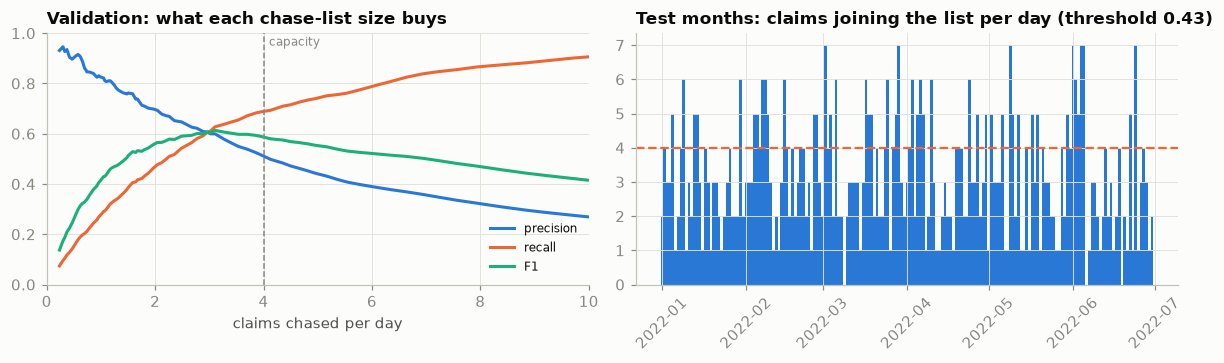

In [12]:
m_test, _ = claim_alerts(te, pred[(CHAMPION, "test")][1], THR[CHAMPION])
_, hit_all = claim_alerts(pre, predict_champ(pre)[1], THR[CHAMPION])    # the team's list: every open claim, whenever it opened
daily = hit_all[(hit_all >= TEST_START) & (hit_all < TEST_END)].dt.floor("D").value_counts().sort_index()
daily = daily.reindex(pd.date_range(TEST_START, TEST_END - pd.Timedelta(days=1)), fill_value=0)
cv = CURVES[CHAMPION]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
for col, color in [("precision", SERIES[0]), ("recall", SERIES[1]), ("F1", SERIES[2])]:
    ax.plot(cv["alerts/day"], cv[col], lw=2, color=color, label=col)
ax.axvline(REVIEW_CAPACITY_PER_DAY, color=MUTED, ls="--", lw=1); ax.text(REVIEW_CAPACITY_PER_DAY + 0.1, 0.95, "capacity", color=MUTED, fontsize=8)
ax.set_xlim(0, 10); ax.set_ylim(0, 1); ax.set_xlabel("claims chased per day"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Validation: what each chase-list size buys")
ax = axes[1]
ax.bar(daily.index, daily.values, width=1, color=SERIES[0])
ax.axhline(REVIEW_CAPACITY_PER_DAY, color=SERIES[1], lw=1.5, ls="--")
ax.set_title(f"Test months: claims joining the list per day (threshold {THR[CHAMPION]:.2f})"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
summary = pd.Series({"claims opened": f"{cases.period.eq('test').sum():,}", "breaches per day": f"{m_test['breaches/day']:.2f}",
                     "chased per day": f"{m_test['alerts/day']:.2f}", "precision": f"{m_test['precision']:.3f}",
                     "recall": f"{m_test['recall']:.3f}", "F1": f"{m_test['F1']:.3f}",
                     "median warning before the deadline (days)": f"{m_test['median lead (days)']:.1f}",
                     "alerts raised after the deadline": m_test["alerts after deadline"],
                     f"days with more than {REVIEW_CAPACITY_PER_DAY} joining (of {len(daily)})": int((daily > REVIEW_CAPACITY_PER_DAY).sum())})
display(summary.to_frame("test, Jan – Jun 2022"))

The transition system wins on validation (F1 0.613) and becomes the champion. On the test months it chases 3.2 claims a day and catches **61 % of the 3.1 claims a day that will miss the SLA, a median 7.4 days before the deadline**, at 59 % precision; 5 are flagged only after their deadline. The daily count is a queue, not a quota: on 45 of 181 days more than four claims join, so the list needs a carry-over rule (task C3).

In [13]:
# The board's question on one morning: which open claims will breach?
openc = cases[(cases.start <= SNAPSHOT) & (cases.paid > SNAPSHOT)]
latest = pre[pre.case_id.isin(openc.index) & (pre.timestamp <= SNAPSHOT)].sort_values("timestamp").groupby("case_id").tail(1)
snap = openc.join(latest.assign(p=predict_champ(latest)[1]).set_index("case_id")[["p", "activity"]])
listed = snap.p >= THR[CHAMPION]
print(f"{SNAPSHOT:%A %d %B %Y, %H:%M}: {len(openc)} claims open · {int(openc.breach.sum())} of them will miss the SLA · "
      f"on the chase list: {int(listed.sum())}, of which {int(snap.breach[listed].sum())} will breach · "
      f"breaches not on the list: {int(snap.breach[~listed].sum())}")
display(snap.groupby("activity", observed=True).agg(open=("p", "size"), on_list=("p", lambda s: int((s >= THR[CHAMPION]).sum())),
                                                    will_breach=("breach", "sum")).rename_axis("last event").T)

Wednesday 01 June 2022, 09:00: 793 claims open · 117 of them will miss the SLA · on the chase list: 24, of which 18 will breach · breaches not on the list: 99


last event,Assign,Decision,FNOL,Reserve
open,129,133,399,132
on_list,0,12,0,12
will_breach,21,24,48,24


The board asked *which open claims will breach*. On the morning of 1 June 2022, 793 claims were open and 117 would miss the SLA. The list held 24, of which 18 did. Of the 99 it missed, 69 had not yet reached a decision, before which the list rarely fires; half the open book (399 claims) was still waiting to be assigned. **The operational answer is to shorten the assignment queue**; a model can only rank claims that have moved.

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test; `simulate_rule` is reused in Section 7.*

Four things a careless version would have done, each flattering a number or a finding.

**Trap 1 — splitting prefixes at random.** A claim's four prefixes share its outcome. Shuffle prefixes into train and test and almost every test claim has a sibling in training, which the model can recognise.

In [14]:
# Trap 1: split the prefixes at random, ignoring that four of them belong to the same claim
LGB_CASE = SEQ + CASE
pool = np.flatnonzero(pre.period.isin(["train", "valid", "gap", "test"]).to_numpy())
i_tr, i_te = train_test_split(pool, test_size=0.3, random_state=SEED)
g_tr, g_te = next(GroupShuffleSplit(1, test_size=0.3, random_state=SEED).split(pool, groups=pre.case_id.to_numpy()[pool]))
t1 = []
for name, a, b in [("random split of prefixes ⚠", pre.iloc[i_tr], pre.iloc[i_te]),
                   ("random split of claims (grouped)", pre.iloc[pool[g_tr]], pre.iloc[pool[g_te]]),
                   ("forward in time, by claim start (honest)", tr, te)]:
    rem, p = LGBPrefix(LGB_CASE).fit(a).predict(b)
    t1.append({"split": name, "MAE (days)": np.abs(rem - b.remaining_h).mean() / 24, "AUPRC": average_precision_score(b.breach, p),
               "test claims also in training": f"{b.case_id.isin(set(a.case_id)).mean():.0%}"})
print(f"distinct claim amounts: {cases.claim_amount.nunique():,} for {len(cases):,} claims — the amount alone almost identifies the claim")
display(pd.DataFrame(t1).set_index("split").style.format({"MAE (days)": "{:.3f}", "AUPRC": "{:.3f}"}))

distinct claim amounts: 29,519 for 30,000 claims — the amount alone almost identifies the claim


,MAE (days),AUPRC,test claims also in training
split,,,
random split of prefixes ⚠,2.436,0.490,97%
random split of claims (grouped),2.469,0.414,0%
"forward in time, by claim start (honest)",2.453,0.415,0%


AUPRC rises from 0.415 to 0.490 under the random split and falls back to 0.414 once claims are kept whole. MAE barely moves (2.44 against 2.45 days): the breach is the claim-level fact the model memorises, through near-unique values such as the amount. In a real log, claims sharing a customer or garage can leak the same way.

**Trap 2 — features computed from the full trace.** "How slowly is this claim being handled?" is a fair question, and `groupby("case_id").wait_h.transform("mean")` a natural way to ask it. But that mean includes the waits still to come.

In [15]:
# Trap 2: a "how slow is this claim being handled" feature computed over the whole trace, against the as-of version
w = ev[["case_id", "timestamp"]].copy()
w["wait_h"] = w.groupby("case_id").timestamp.diff().dt.total_seconds() / 3600
pre["case_mean_wait_h"] = pre.case_id.map(w.groupby("case_id").wait_h.mean())                 # ⚠ uses the claim's future
pre["mean_wait_so_far_h"] = (pre.elapsed_h / (pre.k - 1)).where(pre.k > 1)                     # as-of: only events seen so far
tr, te = pre[P["train"]], pre[P["test"]]
t2 = [{"features": "sequence only (Section 4)", "MAE (days)": res.loc["LightGBM · sequence only", "MAE (days)"], "AUPRC": res.loc["LightGBM · sequence only", "AUPRC"]}]
for name, extra in [("+ mean wait, as-of", ["mean_wait_so_far_h"]), ("+ mean wait over the full trace ⚠", ["case_mean_wait_h"])]:
    rem, p = LGBPrefix(SEQ + extra).fit(tr).predict(te)
    t2.append({"features": name, "MAE (days)": np.abs(rem - te.remaining_h).mean() / 24, "AUPRC": average_precision_score(te.breach, p)})
display(pd.DataFrame(t2).set_index("features").style.format("{:.3f}"))

,MAE (days),AUPRC
features,,
sequence only (Section 4),2.454,0.417
"+ mean wait, as-of",2.454,0.420
+ mean wait over the full trace ⚠,1.334,0.787


The full-trace mean halves the error (2.45 → 1.33 days) and nearly doubles AUPRC (0.417 → 0.787): it is the answer, divided by five. The as-of version adds nothing (0.420).

**Trap 3 — generator artefacts read as findings.** Three statements a process-mining report on this log would make, checked.

In [16]:
# Trap 3: generator artefacts that read like findings
neg_wait = (waits[ACTS[1:]] < 0).any(axis=1).reindex(cases.index)
in_file_order = ev.sort_values(["case_id", "file_seq"]).groupby("case_id").activity.agg(">".join)
p_neg = 1 - np.prod([norm.cdf(step_stats.loc[a, "median_h"] / step_stats.loc[a, "sd_h"]) for a in ACTS[2:]])
print(f"deviating claims by timestamp: {int((~conf).sum())} · claims with a negative drawn wait: {int(neg_wait.sum())} · "
      f"the same claims: {bool((neg_wait == ~conf).all())} · variants in file order: {in_file_order.nunique()} · "
      f"share expected from four normal waits (Section 2's medians and spreads) to have one below zero: {p_neg:.2%}")
hrs = ev.join(cases.user_type.rename("ut"), on="case_id")
office = (hrs.timestamp.dt.day_of_week < 5) & hrs.timestamp.dt.hour.between(8, 17)
print(f"events by human handlers inside office hours (Mon–Fri 08–18): {office[hrs.ut == 'Human'].mean():.1%} "
      f"(uniform clock: {5 * 10 / 168:.1%}) · events on Sundays: {(hrs.timestamp.dt.day_of_week == 6).mean():.1%}")
by_type = cases[cases.period == "train"].groupby("user_type", observed=True).to_pay_h.agg(["size", "median"])
print("median days to payment by handler type:", {k: round(v / 24, 2) for k, v in by_type["median"].items()})
corr = cases[["to_pay_h", "claim_amount", "claimant_age", "car_year"]].corr().loc["to_pay_h"].drop("to_pay_h")
print("correlation of days to payment with:", corr.round(3).to_dict())
rem, p = LGBPrefix(SEQ + CASE).fit(tr).predict(te)
print(f"LightGBM sequence only: MAE {res.loc['LightGBM · sequence only', 'MAE (days)']:.3f} d, AUPRC {res.loc['LightGBM · sequence only', 'AUPRC']:.3f} · "
      f"+ claim attributes: MAE {np.abs(rem - te.remaining_h).mean() / 24:.3f} d, AUPRC {average_precision_score(te.breach, p):.3f}")

deviating claims by timestamp: 735 · claims with a negative drawn wait: 735 · the same claims: True · variants in file order: 1 · share expected from four normal waits (Section 2's medians and spreads) to have one below zero: 2.39%


events by human handlers inside office hours (Mon–Fri 08–18): 29.9% (uniform clock: 29.8%) · events on Sundays: 14.3%
median days to payment by handler type: {'Human': 30.11, 'RPA': 30.07}
correlation of days to payment with: {'claim_amount': -0.002, 'claimant_age': 0.003, 'car_year': 0.015}


LightGBM sequence only: MAE 2.454 d, AUPRC 0.417 · + claim attributes: MAE 2.453 d, AUPRC 0.415


- *"735 claims break the process; 178 were closed before payment."* They are exactly the claims in which a normal wait came out negative (four such waits predict 2.39 %; observed 2.45 %). In file order the log has one variant.
- *"Handlers work around the clock, and the robots are no faster."* 29.9 % of human-handled events fall in office hours, what a uniform clock gives (29.8 %); 14.3 % of all events fall on Sundays; RPA and human claims take 30.07 and 30.11 days.
- *"Claim attributes do not predict delays."* True here (correlations within ±0.02; AUPRC 0.415 with them, 0.417 without), because the generator never used them, which says nothing about a real claims operation.

The 178 warrant a data-quality ticket against the extract, not a compliance case (task E3).

**Trap 4 — rework loops inflate the wrong step (simulated).** The free log has no rework, so we simulate a rule that creates it, reused in Section 7: from 1 October 2022, claims of 7,500 or more need documents, so *Claim Decision* is followed by *Request Information* and, once the customer replies, a second *Claim Decision* (27 % loop twice); later events shift. Dashboards often compute step waits from one row per claim, built with `pivot_table(aggfunc="first")` because `pivot` refuses duplicates.

In [17]:
def simulate_rule(ev, start, min_amount, rng, repeat_p=REWORK_REPEAT_P):
    """SIMULATED rule change: claims of `min_amount` or more opened on/after `start` get Claim Decision →
    Request Information → Claim Decision (a second loop with probability repeat_p); every later event moves back."""
    first = ev.groupby("case_id").timestamp.transform("min")
    dec = ev[(first >= start) & (ev.claim_amount >= min_amount) & (ev.activity == "Decision")]
    n = len(dec)
    loops = 1 + (rng.random(n) < repeat_p)
    h1 = np.clip(rng.normal(24, 12, (n, 2)), 1, None)        # Decision → Request Information (hours)
    h2 = np.clip(rng.normal(96, 36, (n, 2)), 4, None)        # Request Information → Decision: the customer replies (hours)
    h1[loops == 1, 1] = 0; h2[loops == 1, 1] = 0
    td = lambda h: pd.to_timedelta(np.round(h * 3600), unit="s")
    rows = []
    for l in range(2):
        m = loops > l
        base = dec.timestamp.to_numpy()[m] + td(h1[m, :l].sum(1) + h2[m, :l].sum(1)).to_numpy()
        rows.append(dec[m].assign(activity="RequestInfo", timestamp=base + td(h1[m, l]).to_numpy()))
        rows.append(dec[m].assign(activity="Decision", timestamp=base + td(h1[m, l] + h2[m, l]).to_numpy()))
    shift = pd.Series(td(h1.sum(1) + h2.sum(1)).to_numpy(), index=dec.case_id.to_numpy())
    later = ev.case_id.isin(shift.index) & (ev.file_seq > ev.case_id.map(dec.set_index("case_id").file_seq).fillna(99))
    out = ev.copy()
    out.loc[later, "timestamp"] = out.loc[later, "timestamp"] + out.loc[later, "case_id"].map(shift).to_numpy()
    out = pd.concat([out] + rows, ignore_index=True).sort_values(["case_id", "timestamp"], kind="stable").reset_index(drop=True)
    return out, set(dec.case_id)

ev_sim, looped = simulate_rule(ev, RULE_CHANGE, HIGH_VALUE, np.random.default_rng(SEED))   # SIMULATED log, used again in Section 7
cases_sim = case_table(ev_sim)
lp = ev_sim[ev_sim.case_id.isin(looped)]
# Trap 4: one row per claim with pivot_table(aggfunc="first") — the step waits a dashboard would show — against the DFG
piv = lp.pivot_table(index="case_id", columns="activity", values="timestamp", aggfunc="first", observed=True)
naive = {f"{a} → {b}": ((piv[b] - piv[a]).dt.total_seconds() / 3600).median() for a, b in zip(ACTS[:-1], ACTS[1:])}
D_sim = dfg(lp).set_index(["prev", "activity"])
honest = {f"{a} → {b}": D_sim.loc[(a, b), "median_wait_h"] if (a, b) in D_sim.index else np.nan for a, b in zip(ACTS[:-1], ACTS[1:])}
t4 = pd.DataFrame({"pivot, first timestamp ⚠ (h)": naive, "directly-follows graph (h)": honest})
for a, b in [("Decision", "RequestInfo"), ("RequestInfo", "Decision")]:
    t4.loc[f"{a} → {b}", "directly-follows graph (h)"] = D_sim.loc[(a, b), "median_wait_h"]
print(f"SIMULATED: {len(looped):,} claims ≥ {HIGH_VALUE:,} opened from {RULE_CHANGE:%d %b %Y} loop through Request Information "
      f"({cases_sim.loc[list(looped), 'n_events'].gt(8).mean():.0%} twice)")
display(t4.style.format("{:.0f}", na_rep="—"))
post = cases_sim[cases_sim.start >= RULE_CHANGE]
lp_c = post.index.isin(looped)
print(f"after the change: days to payment, looped claims mean {post.to_pay_h[lp_c].mean() / 24:.1f} / median {post.to_pay_h[lp_c].median() / 24:.1f} · "
      f"others {post.to_pay_h[~lp_c].mean() / 24:.1f} / {post.to_pay_h[~lp_c].median() / 24:.1f} · breach rate looped {post.breach[lp_c].mean():.0%}, others {post.breach[~lp_c].mean():.0%}")

SIMULATED: 1,452 claims ≥ 7,500 opened from 01 Oct 2022 loop through Request Information (27% twice)


,"pivot, first timestamp ⚠ (h)",directly-follows graph (h)
FNOL → Assign,360,360
Assign → Decision,118,118
Decision → Reserve,262,120
Reserve → Payment,120,120
Payment → Close,117,117
Decision → RequestInfo,—,24
RequestInfo → Decision,—,97


after the change: days to payment, looped claims mean 36.2 / median 35.9 · others 30.1 / 30.2 · breach rate looped 58%, others 11%


The pivot reports that *Set Reserve* now waits 262 hours instead of 120: the loop's time lands on the next step. The DFG puts it where it belongs: 24 hours to request documents, 97 for the customer to reply. Looped claims take 36.2 days to pay (median 35.9) against 30.1, and 58 % breach. A manager reading the pivot would send reserving staff to fix a delay that sits with the customer.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: a rule change the log does not have (simulated)

*Part C · Productionise · what your monitoring plan must catch (C5); reuse `psi` and `monitor`; `why_late` feeds S1.*

The real log has no drift: for three years variant mix and conformance stay where training left them. So we apply Trap 4's **simulated** rule to the stream (claims opened from July 2022), freeze the champion and its threshold, and watch two clocks, as in Task 02:

- **Now**, as events arrive: variant mix (PSI against training), conformance, predicted breach rate, list length. A loop shows about three weeks into the claim.
- **Later**, once claims are paid, a month or more after FNOL: MAE, actual breach rate, recall.

real log, all 37 FNOL months: variant-mix PSI ≤ 0.031 · non-conforming share 1.3%–3.6%


,PSI · variant mix,mean fitness,non-conforming claims,breach rate,predicted breach rate,chased/day ÷ capacity,MAE (days),breach recall
month,,,,,,,,
2022-07,0.003,0.996,0.023,0.101,0.106,0.798,2.406,0.655
2022-08,0.005,0.995,0.031,0.094,0.099,0.677,2.430,0.593
2022-09,0.007,0.996,0.026,0.095,0.105,0.817,2.470,0.718
2022-10,1.673,0.954,0.273,0.224,0.149,1.847,3.243,0.861
2022-11,1.795,0.947,0.302,0.250,0.160,2.058,3.455,0.857
2022-12,1.687,0.949,0.289,0.239,0.156,1.798,3.295,0.816
2023-01,1.705,0.949,0.295,0.256,0.161,2.105,3.466,0.850
2023-02,1.785,0.948,0.301,0.243,0.156,2.018,3.339,0.865
2023-03,1.792,0.948,0.300,0.237,0.152,1.774,3.300,0.827


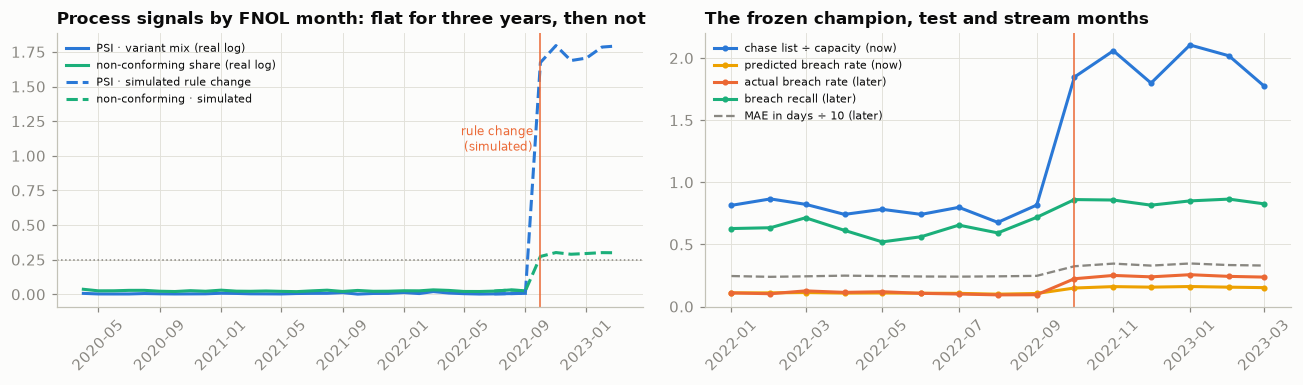

In [18]:
def psi(ref: pd.Series, cur: pd.Series) -> float:
    cats = ref.index.union(cur.index)
    r, c = ref.reindex(cats, fill_value=0) + 1e-4, cur.reindex(cats, fill_value=0) + 1e-4
    return float(((c - r) * np.log(c / r)).sum())

top = cases[cases.period == "train"].variant.value_counts().index[:5]
vmix = lambda c: c.variant.where(c.variant.isin(top), "other").value_counts(normalize=True)
ref_mix = vmix(cases[cases.period == "train"])
cases_sim["fitness"] = [trace_fitness(v.split(">"), REF) for v in cases_sim.variant]

pre_sim = build_prefixes(ev_sim[ev_sim.case_id.isin(cases_sim.index[cases_sim.period == "stream"])], cases_sim, PROCS)
def monitor(c, d):
    rem, p = predict_champ(d)
    d = d.assign(err=np.abs(rem - d.remaining_h) / 24, p=p)
    m = c.groupby("month").apply(lambda g: pd.Series({"PSI · variant mix": psi(ref_mix, vmix(g)), "mean fitness": g.fitness.mean(),
                                                      "non-conforming claims": (g.fitness < 1).mean(), "breach rate": g.breach.mean()}),
                                 include_groups=False)
    m["predicted breach rate"] = d.groupby("case_id").agg(month=("month", "first"), p=("p", "mean")).groupby("month").p.mean()
    per = d.groupby("case_id").agg(month=("month", "first"), hit=("p", "max"), y=("breach", "first"))
    per["hit"] = per.hit >= THR[CHAMPION]
    fnol_days = c.groupby("month").start.agg(lambda s: s.dt.normalize().nunique())       # April 2023 has only 15 days of FNOLs
    m["chased/day ÷ capacity"] = per.groupby("month").hit.sum() / fnol_days / REVIEW_CAPACITY_PER_DAY
    m["MAE (days)"] = d.groupby("month").err.mean()
    m["breach recall"] = per[per.y == 1].groupby("month").hit.mean()
    return m

real = monitor(cases[cases.period.isin(["test", "stream"])], pre[P["test"] | P["stream"]])
sim = monitor(cases_sim[cases_sim.period == "stream"], pre_sim)
sim = sim[sim.index < cases.month.max()]                                 # April 2023 holds 15 days of FNOLs: left out
history = cases.groupby("month").apply(lambda g: pd.Series({"PSI · variant mix": psi(ref_mix, vmix(g)), "non-conforming claims": (g.fitness < 1).mean()}),
                                       include_groups=False)
print(f"real log, all {len(history)} FNOL months: variant-mix PSI ≤ {history['PSI · variant mix'].max():.3f} · "
      f"non-conforming share {history['non-conforming claims'].min():.1%}–{history['non-conforming claims'].max():.1%}")
history = history[history.index < pd.Period(RULE_CHANGE, "M")]          # real log up to the change; the stream after it is simulated

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
t_ = history.index.to_timestamp()
ax.plot(t_, history["PSI · variant mix"], color=SERIES[0], lw=2, label="PSI · variant mix (real log)")
ax.plot(t_, history["non-conforming claims"], color=SERIES[2], lw=2, label="non-conforming share (real log)")
ts_ = sim.index.to_timestamp()
ax.plot(ts_, sim["PSI · variant mix"], color=SERIES[0], lw=2, ls="--", label="PSI · simulated rule change")
ax.plot(ts_, sim["non-conforming claims"], color=SERIES[2], lw=2, ls="--", label="non-conforming · simulated")
ax.axhline(PSI_ALERT, color=MUTED, ls=":", lw=1); ax.axvline(RULE_CHANGE, color=SERIES[1], lw=1)
ax.text(RULE_CHANGE - pd.Timedelta(days=15), ax.get_ylim()[1] * 0.55, "rule change\n(simulated)", color=SERIES[1], fontsize=8, ha="right")
ax.set_title("Process signals by FNOL month: flat for three years, then not"); ax.legend(fontsize=7, loc="upper left")
ax = axes[1]
both = pd.concat([real[real.index < pd.Period(RULE_CHANGE, "M")], sim[sim.index >= pd.Period(RULE_CHANGE, "M")]])
tb_ = both.index.to_timestamp()
ax.plot(tb_, both["chased/day ÷ capacity"], "-o", ms=3, color=SERIES[0], lw=2, label="chase list ÷ capacity (now)")
ax.plot(tb_, both["predicted breach rate"], "-o", ms=3, color=SERIES[3], lw=2, label="predicted breach rate (now)")
ax.plot(tb_, both["breach rate"], "-o", ms=3, color=SERIES[1], lw=2, label="actual breach rate (later)")
ax.plot(tb_, both["breach recall"], "-o", ms=3, color=SERIES[2], lw=2, label="breach recall (later)")
ax.plot(tb_, both["MAE (days)"] / 10, "--", color=MUTED, lw=1.5, label="MAE in days ÷ 10 (later)")
ax.axvline(RULE_CHANGE, color=SERIES[1], lw=1); ax.set_ylim(0, 2.2)
ax.set_title("The frozen champion, test and stream months"); ax.legend(fontsize=7, loc="upper left")
for a_ in axes:
    a_.tick_params(axis="x", rotation=45)
plt.tight_layout()
display(both.loc[both.index >= pd.Period(RULE_CHANGE, "M") - 3].style.format("{:.3f}"))

The process signals fire in the first affected month: variant PSI jumps from below 0.01 to 1.67 (alert at 0.25), the non-conforming share from 2–3 % to 27–30 % (mean fitness 0.996 → 0.95). The champion fails loudly, in the wrong way: recall *rises* (0.82–0.87), as looped claims run late and cross its threshold, but the list grows to 1.8–2.1 times capacity; its predicted breach rate (0.15–0.16) trails the 22–26 % that arrives weeks later; MAE rises from 2.4 to 3.2–3.5 days. Retraining needs months of those labels.

The KB is the faster route: operations publish the rule on the day it starts, as a second process with the new steps and their estimated waits, and the same code reads it. Those estimates equal the simulation's mean waits, which flatters the KB (task E1 makes them wrong).

In [19]:
# Operations publish the rule in the KB on the day it starts: a second process, read by the same code
upd = Graph() + kb
hv_steps = std_steps[:3] + [("RequestInfo", KB_LOOP_TARGET_H[0], 12.0, KB_LOOP_TARGET_H[0] * 1.6),
                            ("Decision", KB_LOOP_TARGET_H[1], 36.0, KB_LOOP_TARGET_H[1] * 1.5)] + std_steps[3:]
upd.add((CP.RequestInfo, RDF.type, CP.Activity)); upd.add((CP.RequestInfo, RDFS.label, Literal("Request Information")))
upd.add((CP.RequestInfo, CP.performedBy, CP.Adjuster))
add_process(upd, "HighValueProcess", hv_steps, RULE_CHANGE, HIGH_VALUE, "Claims of HIGH_VALUE or more need supporting documents (simulated rule)")
ok_u, _ = shacl(upd)
PROCS_U = reference_processes(upd)
pre_sim_u = build_prefixes(ev_sim[ev_sim.case_id.isin(cases_sim.index[cases_sim.period == "stream"])], cases_sim, PROCS_U)
CQ3 = f"""SELECT ?p WHERE {{ ?p a cp:Process ; cp:appliesFrom ?f ; cp:minAmount ?m .
          FILTER(?f <= "2022-11-15"^^xsd:date && ?m <= 8000) }} ORDER BY DESC(?m) LIMIT 1"""
print(f"updated KB: {len(upd)} triples · conforms: {ok_u} · CQ3 · process for a claim of 8,000 opened on 15 Nov 2022: "
      f"{str(list(upd.query(CQ3, initNs={'cp': CP, 'xsd': XSD}))[0][0]).split('#')[1]}")

after = (pre_sim.start >= RULE_CHANGE).to_numpy()
rows = []
for name, d, mdl in [("transition system (frozen)", pre_sim, models["transition system (process-mining baseline)"]),
                     ("LightGBM · sequence only (frozen)", pre_sim, models["LightGBM · sequence only"]),
                     ("LightGBM · sequence + KB conformance, KB not updated", pre_sim, models["LightGBM · sequence + KB conformance"]),
                     ("LightGBM · sequence + KB conformance, KB updated", pre_sim_u, models["LightGBM · sequence + KB conformance"]),
                     ("KB reference process, KB updated", pre_sim_u, None)]:
    d = d[after]
    rem, p = mdl.predict(d) if mdl is not None else kb_predict(d)
    key = {"transition system (frozen)": "transition system (process-mining baseline)",
           "LightGBM · sequence only (frozen)": "LightGBM · sequence only",
           "KB reference process, KB updated": "KB reference process, no training"}.get(name, "LightGBM · sequence + KB conformance")
    hv = (d.claim_amount >= HIGH_VALUE).to_numpy()
    m_, hit = claim_alerts(d, p, THR[key], cases_sim)
    rows.append({"model": name, "MAE (days)": np.abs(rem - d.remaining_h).mean() / 24,
                 "MAE high-value": np.abs(rem - d.remaining_h)[hv].mean() / 24, "AUPRC": average_precision_score(d.breach, p),
                 "chased/day": m_["alerts/day"], "recall": m_["recall"], "median warning (days)": m_["median lead (days)"]})
display(pd.DataFrame(rows).set_index("model").style.format("{:.3f}"))
dev_tr = tr[tr.kb_deviations > 0]
dev_post = pre_sim[after & (pre_sim.kb_deviations > 0).to_numpy()]
print(f"prefixes that deviate from the standard process: remaining time minus the KB's expectation, "
      f"training {(dev_tr.remaining_h - dev_tr.kb_expected_left_h).mean():+.0f} h (n={len(dev_tr):,}) · "
      f"after the change {(dev_post.remaining_h - dev_post.kb_expected_left_h).mean():+.0f} h (n={len(dev_post):,})")

updated KB: 149 triples · conforms: True · CQ3 · process for a claim of 8,000 opened on 15 Nov 2022: HighValueProcess


,MAE (days),MAE high-value,AUPRC,chased/day,recall,median warning (days)
model,,,,,,
transition system (frozen),3.345,4.816,0.676,7.462,0.847,8.820
LightGBM · sequence only (frozen),3.615,5.499,0.496,3.249,0.371,4.980
"LightGBM · sequence + KB conformance, KB not updated",3.457,5.088,0.463,2.558,0.295,5.006
"LightGBM · sequence + KB conformance, KB updated",2.811,3.409,0.704,6.208,0.720,10.834
"KB reference process, KB updated",2.742,3.207,0.788,9.655,0.881,35.000


prefixes that deviate from the standard process: remaining time minus the KB's expectation, training -5 h (n=222) · after the change +52 h (n=5,193)


Here the card's ablation pays off. With the KB updated, the **conformance features lift LightGBM from AUPRC 0.463 to 0.704** on post-change claims and cut the error on high-value claims from 5.1 to 3.4 days, without retraining; warnings come 10.8 days before the deadline, not 5.0. Without the update they hurt: in training a deviation meant a generator artefact and a slightly *shorter* claim (−5 h against the KB's expectation); now it means a loop (+52 h). The KB alone ranks best (AUPRC 0.788) but flags every high-value claim on opening, 9.7 a day for a team of four. Task C5's plan needs all of it: conformance alert, KB update, threshold reset, then a retrain.

In [20]:
# "Why is this claim late?" — the evidence pack a generated explanation may use (task S1), and a template baseline
def why_late(cid, ev_, cases_, procs):
    c = cases_.loc[cid]
    proc = process_of(cases_.loc[[cid]], procs).iat[0]
    steps = procs[proc]["steps"]
    tr_ = ev_[ev_.case_id == cid].sort_values("timestamp")
    trace, seen, rows = tr_.activity.tolist(), {}, []
    occ = {}
    for (a, t), prev in zip(tr_[["activity", "timestamp"]].itertuples(index=False), [None] + tr_.timestamp.tolist()[:-1]):
        occ[a] = occ.get(a, 0) + 1
        ref = [s for s in steps if s[0] == a]
        tgt = ref[min(occ[a], len(ref)) - 1] if ref else None
        wait = None if prev is None else (t - prev).total_seconds() / 3600
        rows.append({"event": a, "at": f"{t:%Y-%m-%d %H:%M}", "wait_h": None if wait is None else round(wait, 1),
                     "target_h": None if tgt is None else tgt[1], "p90_h": None if tgt is None else tgt[3],
                     "over_p90": bool(tgt is not None and wait is not None and wait > tgt[3])})
    return {"claim_ref": hashlib.blake2b(cid.encode(), digest_size=4).hexdigest(), "process": proc,
            "sla_days": SLA_DAYS, "days_to_payment": round(c.to_pay_h / 24, 1),
            "fitness_vs_standard": round(trace_fitness(trace, REF), 3), "trace": rows}

late_ids = cases_sim[(cases_sim.start >= RULE_CHANGE) & (cases_sim.breach == 1) & cases_sim.index.isin(looped)].index
pack = why_late(late_ids[0], ev_sim, cases_sim, PROCS_U)
print(json.dumps(pack, ensure_ascii=False)[:1200])
over = [r for r in pack["trace"] if r["over_p90"]]
loops_ = sum(r["event"] == "RequestInfo" for r in pack["trace"])
print("draft (template baseline):", f"Claim {pack['claim_ref']} was paid after {pack['days_to_payment']} days against a {SLA_DAYS}-day target. "
      + (f"It follows the {pack['process']} ({loops_} request(s) for information). " if loops_ else "")
      + ("Steps that waited longer than 9 in 10 claims: " + ", ".join(f"{r['event']} ({r['wait_h'] / 24:.1f} d vs target {r['target_h'] / 24:.1f} d)" for r in over)
         if over else "No single step was unusually slow; the delay is the sum of ordinary waits."))
print(f"evidence pack: {len(json.dumps(pack, ensure_ascii=False)):,} characters")

{"claim_ref": "aff921b9", "process": "HighValueProcess", "sla_days": 35, "days_to_payment": 38.6, "fitness_vs_standard": 0.857, "trace": [{"event": "FNOL", "at": "2023-03-21 10:12", "wait_h": null, "target_h": 0.0, "p90_h": 0.0, "over_p90": false}, {"event": "Assign", "at": "2023-04-06 21:09", "wait_h": 394.9, "target_h": 359.9, "p90_h": 421.8, "over_p90": false}, {"event": "Decision", "at": "2023-04-11 10:32", "wait_h": 109.4, "target_h": 120.8, "p90_h": 181.1, "over_p90": false}, {"event": "RequestInfo", "at": "2023-04-12 06:54", "wait_h": 20.4, "target_h": 24.0, "p90_h": 38.4, "over_p90": false}, {"event": "Decision", "at": "2023-04-15 01:58", "wait_h": 67.1, "target_h": 96.0, "p90_h": 144.0, "over_p90": false}, {"event": "Reserve", "at": "2023-04-22 21:48", "wait_h": 187.8, "target_h": 120.6, "p90_h": 181.9, "over_p90": true}, {"event": "Payment", "at": "2023-04-29 00:02", "wait_h": 146.2, "target_h": 120.0, "p90_h": 182.4, "over_p90": false}, {"event": "Close", "at": "2023-05-02 1

*Why is this claim late?* The evidence pack holds the trace, the process that applied and each wait against its target and P90, and nothing personal. The template is the baseline a generated answer must beat (task S1).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's plan, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/claims_flow/` (`eventlog` and as-of prefixes, `discovery`, `conformance`, `predict`, `kb`); `GET /claims/{id}/eta` returns remaining days, breach probability, evidence pack. |
| Monitoring (S04) | Now: variant-mix PSI (≤ 0.03 on the real log; 1.67 after the change; alert 0.25), non-conforming share (1.3–3.6 %; 27–30 %), list ÷ capacity (0.7–0.8; 1.8–2.1). Later: MAE (2.4 → 3.2–3.5 days), breach rate, recall. RED metrics. |
| CI/CD gate (S05) | Frozen Jan – Jun 2022 holdout (4,905 claims, SHA-256): MAE within 0.05 days of the noise floor (2.45); breach F1 at four a day ≥ 0.55 (champion 0.601; a placeholder for the business); an as-of feature test. |
| MLflow tracking and registry (S06) | KB process hash (the discovered model), prefix encoding, split dates, SLA, capacity, threshold 0.43, MAE by prefix length, AUPRC, F1; transition system `champion`, LightGBM + KB `challenger`. |
| Offline / online training and serving | Streaming: score at each event before payment, plus a daily timer for claims that have not moved; weekly re-discovery; retrain once labels mature (60 days). |
| Data and model drift | None in the real log (variant PSI ≤ 0.03 over 37 months). Simulated rule: PSI 1.7, fitness 0.996 → 0.95, breach rate 10 % → 22–26 %; a deviation's meaning inverts (−5 h → +52 h). |
| Knowledge base and context (S07–S09) | 84 triples (149 with the new rule): activities, roles, processes and step targets, rules; SHACL. Ablation: no gain on the stable log; AUPRC 0.463 → 0.704 after the change, KB updated. |
| GenAI and context engineering (S10–S11) | "Why is this claim late?" from the evidence pack (about 1,100 characters per claim); a draft customer update; a golden set of late claims with known causes. |
| Governance | Synthetic (ODbL / DbCL); names dropped on load, age never a feature; a fraud flag needs a human approver (SHACL); the list advises, people decide. |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Split by FNOL date, tested; assert that features from a truncated log equal those from the full log; report out-of-order claims rather than re-sort them; compute step waits from the DFG.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `SLA_DAYS` (30–40) and `REVIEW_CAPACITY_PER_DAY` (2–10), decide what a full list does, cost a chase against a breach, and write the ADR the claims-operations head signs.
- **C4 — Package, container, gate.** `src/claims_flow/`, `GET /claims/{id}/eta`, a slim non-root container, and `make ci` gating MAE and breach F1 at capacity on the fingerprinted holdout (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs with the KB hash and fingerprints; `champion` and `challenger` aliases; a model card; a monitoring plan with conformance signals now, MAE and recall later, and the response ladder: KB update, threshold reset, retrain (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation.** Extend the ontology from competency questions (documents per claim type, authority limits), run SHACL in CI, and measure with and without conformance features before and after the change, with `KB_LOOP_TARGET_H` wrong by ±50 % (Sessions 07–09).
- **E2 — Who waits?** Breach rate, list share and warning time by age band and policy type; the GDPR and AI Act position of a system that prioritises claims, as your reading, with sources.
- **E3 — The data-quality case.** The ticket for the 735 out-of-order claims, and what a conformance report may claim meanwhile.
- **E4 — Fraud, separately.** The log has no fraud label: design the human-approval flow the SHACL shape enforces, and say what a fraud model would need.

### Stretch

- **S1 — "Why is this claim late?"** From the evidence pack and KB only, explain the delay and draft the customer update: versioned prompt, structured output, a golden set of 50 late claims with known causes, citation checks, injection tests, cost per answer (Sessions 10–11).
- **S2 — Streaming serving.** Score at each event from a stream (Kafka, or Postgres `LISTEN/NOTIFY`) with a daily timer for stalled claims; latency budget and cost per 1,000 events against a nightly batch.
- **S3 — Retraining policy.** Replay the simulated change with a 60-day label delay: how long does each response (KB update, threshold reset, scheduled or drift-triggered retrain) leave the list over capacity?

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed; names dropped in the loader
- [ ] `README.md` states the split dates, the SLA and capacity assumptions, the simulated rule, and the data source (Kaggle, ODbL / DbCL)
- [ ] Split by FNOL date; as-of prefix features with the truncation test; traps removed
- [ ] Operating point from capacity, with the signed ADR
- [ ] CI gate on the fingerprinted holdout; registered model, model card, monitoring plan with conformance drift and label delay
- [ ] Process ontology with SHACL shapes and the ablation
- [ ] One-page recommendation for the claims-operations head
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `networkx`, `scikit-learn`, `lightgbm`, `scipy`, `matplotlib`, `rdflib`, `pyshacl`, `kagglehub` (pinned in `requirements.txt`). No pm4py: Petri nets and token replay add nothing on a single-path log.
- Alberto (`carlosalvite`) (2023). *Event logs for process mining* (car insurance claims). Kaggle, v1. ODbL / DbCL.
- van der Aalst, W. M. P. (2016). *Process Mining: Data Science in Action*, 2nd ed. Springer.
- van der Aalst, W. M. P., Schonenberg, M. H., Song, M. (2011). *Time prediction based on process mining.* Information Systems 36(2).
- Verenich, I., Dumas, M., La Rosa, M., Maggi, F. M., Teinemaa, I. (2019). *Survey and cross-benchmark comparison of remaining time prediction methods in business process monitoring.* ACM TIST 10(4).
- Teinemaa, I., Dumas, M., La Rosa, M., Maggi, F. M. (2019). *Outcome-oriented predictive process monitoring: review and benchmark.* ACM TKDD 13(2).
- W3C (2017). *Shapes Constraint Language (SHACL).*

In [21]:
print(f"pandas {pd.__version__} · numpy {np.__version__} · networkx {nx.__version__} · lightgbm {lgb.__version__} · "
      f"scikit-learn {sklearn.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time() - T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · networkx 3.7 · lightgbm 4.7.0 · scikit-learn 1.9.1 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 233s
